In [1]:
import os
from scipy.interpolate import CubicSpline
from matplotlib import pyplot as plt
import scipy.io as sio
import numpy as np
import copy
import json
from utils.helper import aoa_sim_1_sat_loc, range_estimation

Specify the index of data files, 11 in total

In [2]:
file_idx = 10 # 0-10

Load Starloc configurations

In [3]:
from utils.helper import get_data_configs

data_root_folder = 'data/'

# system parameters                    
fc = 11.325e9                                                       # carrier frequency in Hz
lam = 299792458 / fc                                                # wavelength in meters
sample_rate = 2e6                                                   # sample rate (bandwidth) in Hz
d = 13.25e-2                                                        # antenna spacing in meters
stft_win = 14e-3                                                    # STFT window length in seconds
stft_win_len = int(stft_win * sample_rate)                          # STFT window length
f = np.linspace(-sample_rate/2, sample_rate/2, int(stft_win_len))   # frequency bins for STFT

start_time, date, lat_gt, lon_gt, alt_gt, yaw, pitch, roll = get_data_configs(data_root_folder, file_idx)
# reads data cappture start timestamp in seconds, capture date, Starloc's location latitude (deg), longitude (deg), altitude (m), and Starloc's orientation (yaw, pitch, roll) in degrees
print('Starloc location lat (deg), lon (deg), alt (m): ', lat_gt, lon_gt, alt_gt)


Starloc location lat (deg), lon (deg), alt (m):  40.072148640919394 -88.20947973527183 184.7533703368256


Load the satellite signal

In [4]:
%matplotlib inline
data_folder = os.path.join(data_root_folder, date)
tones_dict = sio.loadmat(os.path.join(data_folder, 'tracked_tones.mat'))['tones_dict']
main_tone_dict = sio.loadmat(os.path.join(data_folder, 'tracked_tones.mat'))['main_tone_dict']
id_dict = sio.loadmat(os.path.join(data_folder, 'tracked_tones.mat'))['id_dict']
ref_sig_idx = sio.loadmat(os.path.join(data_folder, 'calibration.mat'))['ref_sig_idx']
phase_offset_01 = sio.loadmat(os.path.join(data_folder, 'calibration.mat'))['phase_offset_01'].T
phase_offset_21 = sio.loadmat(os.path.join(data_folder, 'calibration.mat'))['phase_offset_21'].T
sat_num = len(tones_dict[0, :])

doppler tracking - 9 tones

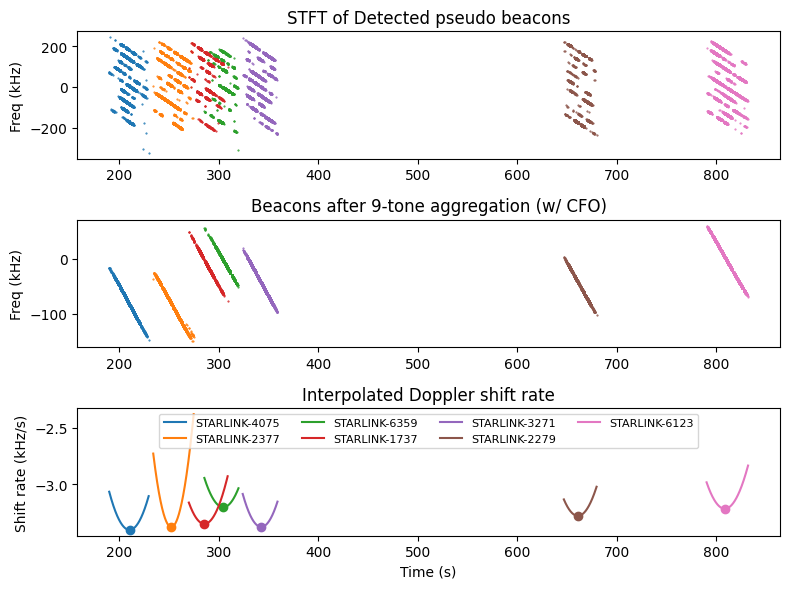

In [5]:
time_arr, dopp_coeff_list = [], []
fig = plt.figure(figsize=(8,6))
for sat_idx in range(sat_num):
    ## 9 tone dopp track 
    tones = tones_dict[0, sat_idx]
    tones_time = tones[:, 0].real # time in seconds
    tones_freq_bin = tones[:, 1].real # frequency bin index
    tones_freq = f[np.array(tones_freq_bin, dtype=int)] # frequency in Hz
    plt.subplot(3, 1, 1)
    plt.plot(tones_time, tones_freq/1e3, '.', markersize=1, label=id_dict[0, sat_idx][0])
    plt.title('STFT of Detected pseudo beacons')
    plt.ylabel('Freq (kHz)')

    # aggregate 9 tones using the prior knowledge that these tones' frequency spacing is 43945.5 Hz
    main_tone = main_tone_dict[0, sat_idx]
    main_tone_time, main_tone_freq = main_tone[:, 0].real, main_tone[:, 1].real
    main_tone_start, main_tone_end = np.min(main_tone_time), np.max(main_tone_time)
    p = np.polyfit(main_tone_time, main_tone_freq, 1)
    tone_freq_spacing = 43945.5 # Hz
    for t_idx in range(len(tones_time)):
        t_i = tones_time[t_idx]
        tones_freq_i = tones_freq[t_idx]
        dopp_i = np.polyval(p, t_i)
        f_offset = tones_freq_i - dopp_i
        n_tones_offset = np.round(f_offset / tone_freq_spacing)
        tones_freq[t_idx] = tones_freq_i - n_tones_offset * tone_freq_spacing
    
    plt.subplot(3, 1, 2)
    plt.plot(tones_time, tones_freq/1e3, '.', markersize=1, label=id_dict[0, sat_idx][0])
    plt.title('Beacons after 9-tone aggregation (w/ CFO)')
    plt.ylabel('Freq (kHz)')

    t_sat_start, t_sat_end = np.min(tones_time), np.max(tones_time)
    p = np.polyfit(tones_time, tones_freq, 3)
    t = np.arange(t_sat_start, t_sat_end, 0.001)
    freqs_polyfit = np.polyval(p, t)/1e3
    freqs_diff = np.diff(freqs_polyfit) / np.diff(t)
    t_diff = t[0:-1] + (t[1]-t[0])/2
    # find the min value of the derivative
    min_idx = np.argmin(freqs_diff)
    if -p[1]/(3*p[0]) < t_sat_start or -p[1]/(3*p[0]) > t_sat_end:
        time_arr.append(t_diff[min_idx])
    else:
        time_arr.append(-p[1]/(3*p[0]))
    dopp_coeff_list.append(p)
    plt.subplot(3, 1, 3)
    plt.plot(t_diff, freqs_diff, label=id_dict[0, sat_idx][0], markersize=2)
    plt.scatter(t_diff[min_idx], freqs_diff[min_idx])
    plt.legend(loc='upper center', ncols=4, fontsize=8)
    plt.title('Interpolated Doppler shift rate')
    plt.xlabel('Time (s)')
    plt.ylabel('Shift rate (kHz/s)')
    plt.tight_layout()

Time to get the phase differences and calibrate for orientation, and other phase offsets

/opt/anaconda3/envs/starloc/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/opt/anaconda3/envs/starloc/lib/python3.9/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


gap_arr_mean:  -8.232722353858906 11.990032521157557 


gap_arr_std:  0.08269000642177296 0.07904053654307651 


0 [ 3.03961093e-04  1.50209767e-01 -4.26603033e+01] [-5.81516820e-04 -7.76473632e-02  4.42089235e+01]
1 [ 6.01527685e-04 -5.61432368e-01  1.01230469e+02] [ 8.47040216e-05 -3.54091899e-01  8.63071517e+01]
2 [-2.96176911e-05 -1.14495238e-01  3.40879954e+01] [-2.40562063e-04 -2.27355484e-01  9.67085076e+01]
3 [-1.87219859e-04  3.64505212e-01 -9.08903391e+01] [ 6.44789168e-04 -6.90389271e-01  1.48889192e+02]
4 [-8.47970447e-05 -2.17747927e-01  7.38776198e+01] [-1.08391998e-04 -2.34754261e-01  9.68756143e+01]
5 [-5.35495694e-04  4.36515008e-01 -6.17630074e+01] [ 6.26804463e-04 -1.12335392e+00  4.75948353e+02]
6 [ 1.57290456e-04 -3.79039924e-01  2.03327702e+02] [ 2.62303627e-04 -8.00286142e-01  4.75368945e+02]


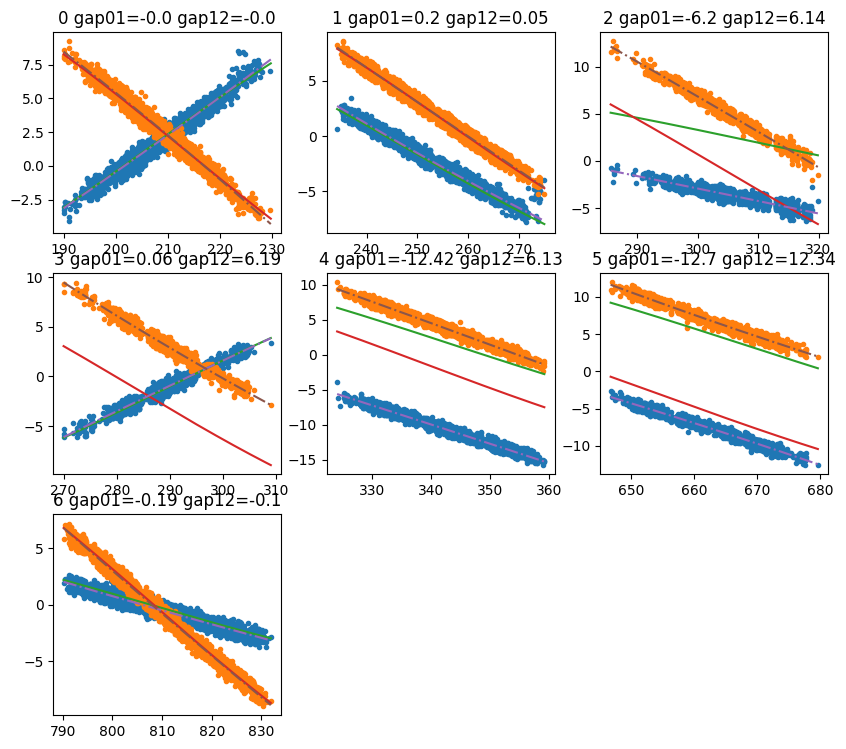

In [6]:
# first cheat by using the gt location to get the random phase offset (mean value for all satellites)
### Predefining variables
gap_01_arr, gap_12_arr, gap_01_coarse_arr, gap_12_coarse_arr = np.array([]), np.array([]), np.array([]), np.array([]) # one gap for each satellite
az_gt_list, el_gt_list, range_gt_list, az_coarse_list, el_coarse_list, range_coarse_list, timestamps_list = [], [], [], [], [], [], [] # each list has one entry for each satellite
sat_loc_gt_list, sat_loc_coarse_list = [], [] # each list has one entry for each satellite
dopp_gt_list = []
del_phi_01_polyfit_list, del_phi_12_polyfit_list, del_phi_01_polyfit_coarse_gt_list, del_phi_12_polyfit_coarse_gt_list = [], [], [], []
del_phi_01_alltones_list, del_phi_12_alltones_list, del_phi_01_gt_list, del_phi_12_gt_list, del_phi_01_coarse_gt_list, del_phi_12_coarse_gt_list, del_phi_01_polyfit_gt_list, del_phi_12_polyfit_gt_list = [], [], [], [], [], [], [], []

### Rx antenna locations
rx_loc_1, rx_loc_0, rx_loc_2 = np.array([0,0,0]), np.array([0,-d,0]), np.array([d,0,0])

# get the rotation matrix
R_yaw = np.array([[np.cos(np.deg2rad(yaw)), -np.sin(np.deg2rad(yaw)), 0], [np.sin(np.deg2rad(yaw)), np.cos(np.deg2rad(yaw)), 0], [0, 0, 1]])
R_pitch = np.array([[np.cos(np.deg2rad(pitch)), 0, np.sin(np.deg2rad(pitch))], [0, 1, 0], [-np.sin(np.deg2rad(pitch)), 0, np.cos(np.deg2rad(pitch))]])
R_roll = np.array([[1, 0, 0], [0, np.cos(np.deg2rad(roll)), -np.sin(np.deg2rad(roll))], [0, np.sin(np.deg2rad(roll)), np.cos(np.deg2rad(roll))]])
R = R_yaw @ R_pitch @ R_roll

# rotate the rx locations
rx_loc_0, rx_loc_2 = R @ rx_loc_0, R @ rx_loc_2

tmp_to_add_arr_01 = []
tmp_to_add_arr_12 = []
for sat_idx in range(sat_num):
    sat_dopp_track = tones_dict[0, sat_idx]
    t = sat_dopp_track[:, 0].real
    t_sat_start, t_sat_end = np.min(t), np.max(t)
    phi0_alltones = np.angle(sat_dopp_track[:, 2])
    phi1_alltones = np.angle(sat_dopp_track[:, 3])
    phi2_alltones = np.angle(sat_dopp_track[:, 4])
    del_phi_01_alltones = np.unwrap(phi0_alltones-phi1_alltones)
    del_phi_12_alltones = np.unwrap(phi1_alltones-phi2_alltones)
    
    # conpensate phase phase_offset from ref sig
    ref_sig_ii = np.argmin(np.abs(ref_sig_idx[:, 0]/sample_rate-(t_sat_start+t_sat_end)/2))
    phase_offset_01_ = phase_offset_01[ref_sig_ii]
    phase_offset_12_ = -phase_offset_21[ref_sig_ii]
    # subtract phase_offset from ref sig
    del_phi_01_alltones -= phase_offset_01_
    del_phi_12_alltones -= phase_offset_12_

    ### Get the ground truth del_phi_01 and del_phi_12 using the gt location
    t_sim, az_gt, el_gt, range_gt, sat_loc_gt, dopp_gt = aoa_sim_1_sat_loc(data_folder, data_folder+'/Starlink.tle', id_dict[0,sat_idx][0], start_time+t_sat_start, start_time+t_sat_end, .1, lat_gt, lon_gt, alt_gt)
    timestamps = t_sim+t_sat_start

    dopp_gt_list.append(dopp_gt)
    az_gt, el_gt = np.deg2rad(az_gt), np.deg2rad(el_gt)
    az_gt_list.append(az_gt)
    el_gt_list.append(el_gt)
    range_gt_list.append(range_gt)
    sat_loc_gt_list.append(sat_loc_gt)
    timestamps_list.append(timestamps)

    # considering the gt location as origin, get location of satellite
    loc_sat_wrt_gt = np.array([range_gt*np.cos(el_gt)*np.sin(az_gt), range_gt*np.cos(el_gt)*np.cos(az_gt), range_gt*np.sin(el_gt)]).T

    # get phase difference between the rx antennas given the location of the satellite wrt gt location
    distance_bw_rx0_satloc_gt = np.linalg.norm(loc_sat_wrt_gt - rx_loc_0, axis=1)
    distance_bw_rx1_satloc_gt = np.linalg.norm(loc_sat_wrt_gt - rx_loc_1, axis=1)
    distance_bw_rx2_satloc_gt = np.linalg.norm(loc_sat_wrt_gt - rx_loc_2, axis=1)
    del_phi_01_gt = -2*np.pi*(distance_bw_rx0_satloc_gt - distance_bw_rx1_satloc_gt)/lam
    del_phi_12_gt = -2*np.pi*(distance_bw_rx1_satloc_gt - distance_bw_rx2_satloc_gt)/lam
    p_del_phi_01_gt = np.polyfit(timestamps, del_phi_01_gt, 2)
    p_del_phi_12_gt = np.polyfit(timestamps, del_phi_12_gt, 2)
    del_phi_01_gt_list.append(del_phi_01_gt)
    del_phi_12_gt_list.append(del_phi_12_gt)
    del_phi_01_polyfit_gt_list.append(p_del_phi_01_gt)
    del_phi_12_polyfit_gt_list.append(p_del_phi_12_gt)

    p_del_phi_01 = np.polyfit(t, del_phi_01_alltones, 2, w = np.minimum(np.abs(sat_dopp_track[:, 2]), np.abs(sat_dopp_track[:, 3])))
    p_del_phi_12 = np.polyfit(t, del_phi_12_alltones, 2, w = np.minimum(np.abs(sat_dopp_track[:, 3]), np.abs(sat_dopp_track[:, 4])))
    del_phi_01_fit = np.polyval(p_del_phi_01, timestamps)
    del_phi_12_fit = np.polyval(p_del_phi_12, timestamps)
    sig_del_phi_01 = np.abs(np.polyval(p_del_phi_01, t) - del_phi_01_alltones)
    sig_del_phi_12 = np.abs(np.polyval(p_del_phi_12, t) - del_phi_12_alltones)

    gap_01_coarse = np.mean(del_phi_01_gt - del_phi_01_fit)
    gap_12_coarse = np.mean(del_phi_12_gt - del_phi_12_fit)

    add_tmp_01 = 0
    add_tmp_12 = 0
    del_phi_01_alltones_orig = copy.deepcopy(del_phi_01_alltones)
    del_phi_12_alltones_orig = copy.deepcopy(del_phi_12_alltones)

    while np.abs(gap_01_coarse-np.mean(gap_01_coarse_arr)) > 1.5*np.pi:
        tmp = 2*np.pi*np.sign(gap_01_coarse-np.mean(gap_01_arr))
        gap_01_coarse -= tmp
        del_phi_01_alltones += tmp
        add_tmp_01 += tmp
        # print("rm_pi_gap_01", sat_idx, add_tmp_01)
    while np.abs(gap_12_coarse-np.mean(gap_12_coarse_arr)) > 1.5*np.pi:
        tmp = 2*np.pi*np.sign(gap_12_coarse-np.mean(gap_12_arr))
        gap_12_coarse -= tmp
        del_phi_12_alltones += tmp
        add_tmp_12 += tmp
        # print("rm_pi_gap_12", sat_idx, add_tmp_12)

    del_phi_01_alltones_list.append(del_phi_01_alltones_orig)
    del_phi_12_alltones_list.append(del_phi_12_alltones_orig)
    p_del_phi_01_refit = np.polyfit(t, del_phi_01_alltones, 2, w = np.minimum(np.abs(sat_dopp_track[:, 2]), np.abs(sat_dopp_track[:, 3]))/sig_del_phi_01)
    p_del_phi_12_refit = np.polyfit(t, del_phi_12_alltones, 2, w = np.minimum(np.abs(sat_dopp_track[:, 3]), np.abs(sat_dopp_track[:, 4]))/sig_del_phi_12)

    gap_01 = np.mean(del_phi_01_gt - np.polyval(p_del_phi_01_refit, timestamps))
    gap_12 = np.mean(del_phi_12_gt - np.polyval(p_del_phi_12_refit, timestamps))
    gap_01_arr = np.append(gap_01_arr, gap_01)
    gap_12_arr = np.append(gap_12_arr, gap_12)
    gap_01_coarse_arr = np.append(gap_01_coarse_arr, gap_01_coarse)
    gap_12_coarse_arr = np.append(gap_12_coarse_arr, gap_12_coarse)
    tmp_to_add_arr_01.append(add_tmp_01)
    tmp_to_add_arr_12.append(add_tmp_12)
    p_del_phi_01_refit_orig = np.polyfit(t, del_phi_01_alltones_orig, 2, w = np.minimum(np.abs(sat_dopp_track[:, 2]), np.abs(sat_dopp_track[:, 3]))/sig_del_phi_01)
    p_del_phi_12_refit_orig = np.polyfit(t, del_phi_12_alltones_orig, 2, w = np.minimum(np.abs(sat_dopp_track[:, 3]), np.abs(sat_dopp_track[:, 4]))/sig_del_phi_12)

    del_phi_01_polyfit_list.append(p_del_phi_01_refit_orig)
    del_phi_12_polyfit_list.append(p_del_phi_12_refit_orig)
    # print("del_phi_coeffs", p_del_phi_01_refit-p_del_phi_01_gt, p_del_phi_01_coarse_gt-p_del_phi_01_gt, p_del_phi_12_refit-p_del_phi_12_gt, p_del_phi_12_coarse_gt-p_del_phi_12_gt)
del_phi_01_polyrefit_list, del_phi_12_polyrefit_list = [], []
del_phi_01_alltones_comp_list, del_phi_12_alltones_comp_list = [], []
print("gap_arr_mean: ", np.mean(gap_01_arr[0:3]), np.mean(gap_12_arr[0:3]), "\n\n")
print("gap_arr_std: ", np.std(gap_01_arr[0:3]), np.std(gap_12_arr[0:3]), "\n\n")
train_num = 1
plt.figure(figsize=(10, 12))
for sat_idx in range(sat_num):
    sat_dopp_track = tones_dict[0, sat_idx]
    t = sat_dopp_track[:, 0].real
    plt.subplot(4,3,sat_idx+1)
    del_phi_01_alltones_gapcompensated = del_phi_01_alltones_list[sat_idx]+np.mean(gap_01_arr[0:train_num])
    del_phi_12_alltones_gapcompensated = del_phi_12_alltones_list[sat_idx]+np.mean(gap_12_arr[0:train_num])
    del_phi_01_alltones_comp_list.append(del_phi_01_alltones_gapcompensated)
    del_phi_12_alltones_comp_list.append(del_phi_12_alltones_gapcompensated)
    plt.plot(t, del_phi_01_alltones_gapcompensated, '.', label='rx0 - rx1')
    plt.plot(t, del_phi_12_alltones_gapcompensated, '.', label='rx1 - rx2')

    # plt.plot(timestamps_list[sat_idx], np.polyval(del_phi_01_polyfit_list[sat_idx], timestamps_list[sat_idx]), label='rx0 - rx1 fit', linestyle='--')
    # plt.plot(timestamps_list[sat_idx], np.polyval(del_phi_12_polyfit_list[sat_idx], timestamps_list[sat_idx]), label='rx1 - rx2 fit', linestyle='--')

    plt.plot(timestamps_list[sat_idx], del_phi_01_gt_list[sat_idx], label='rx0 - rx1 gt')
    plt.plot(timestamps_list[sat_idx], del_phi_12_gt_list[sat_idx], label='rx1 - rx2 gt')
    # plt.plot(timestamps_list[sat_idx], del_phi_01_coarse_gt_list[sat_idx], label='rx0 - rx1 coarse gt', linestyle=':')
    # plt.plot(timestamps_list[sat_idx], del_phi_12_coarse_gt_list[sat_idx], label='rx1 - rx2 coarse gt', linestyle=':')

    del_phi_01_ = np.polyval(del_phi_01_polyfit_list[sat_idx], timestamps_list[sat_idx])
    del_phi_12_ = np.polyval(del_phi_12_polyfit_list[sat_idx], timestamps_list[sat_idx])
    # add the gap
    del_phi_01_ += np.mean(gap_01_arr[0:train_num])
    del_phi_12_ += np.mean(gap_12_arr[0:train_num])

    # refit the polynomial
    p_del_phi_01_refit_ = np.polyfit(timestamps_list[sat_idx], del_phi_01_, 2)
    p_del_phi_12_refit_ = np.polyfit(timestamps_list[sat_idx], del_phi_12_, 2)
    plt.plot(timestamps_list[sat_idx], np.polyval(p_del_phi_01_refit_, timestamps_list[sat_idx]), label='rx0 - rx1 refit', linestyle='-.')
    plt.plot(timestamps_list[sat_idx], np.polyval(p_del_phi_12_refit_, timestamps_list[sat_idx]), label='rx1 - rx2 refit', linestyle='-.')
    plt.title(str(sat_idx)+' gap01='+str(round(np.mean(del_phi_01_-np.polyval(del_phi_01_polyfit_gt_list[sat_idx], timestamps_list[sat_idx])),2))+' gap12='+str(round(np.mean(del_phi_12_-np.polyval(del_phi_12_polyfit_gt_list[sat_idx], timestamps_list[sat_idx])),2)))

    print(sat_idx, p_del_phi_01_refit_, p_del_phi_12_refit_)
    del_phi_01_polyrefit_list.append(p_del_phi_01_refit_)
    del_phi_12_polyrefit_list.append(p_del_phi_12_refit_)

Satellite index:  0


/var/folders/2k/nst1mls11d9_hrj8jjh1vpkh0000gn/T/ipykernel_25909/1563497416.py:77: RuntimeWarning: invalid value encountered in arccos
  el_fin = np.arccos(-del_phi_01*lam/(2*np.pi*d*np.cos(az_fin)))


Satellite index:  1
Satellite index:  2
Satellite index:  3
debug here
debug here
Satellite index:  4
Satellite index:  5
Satellite index:  6


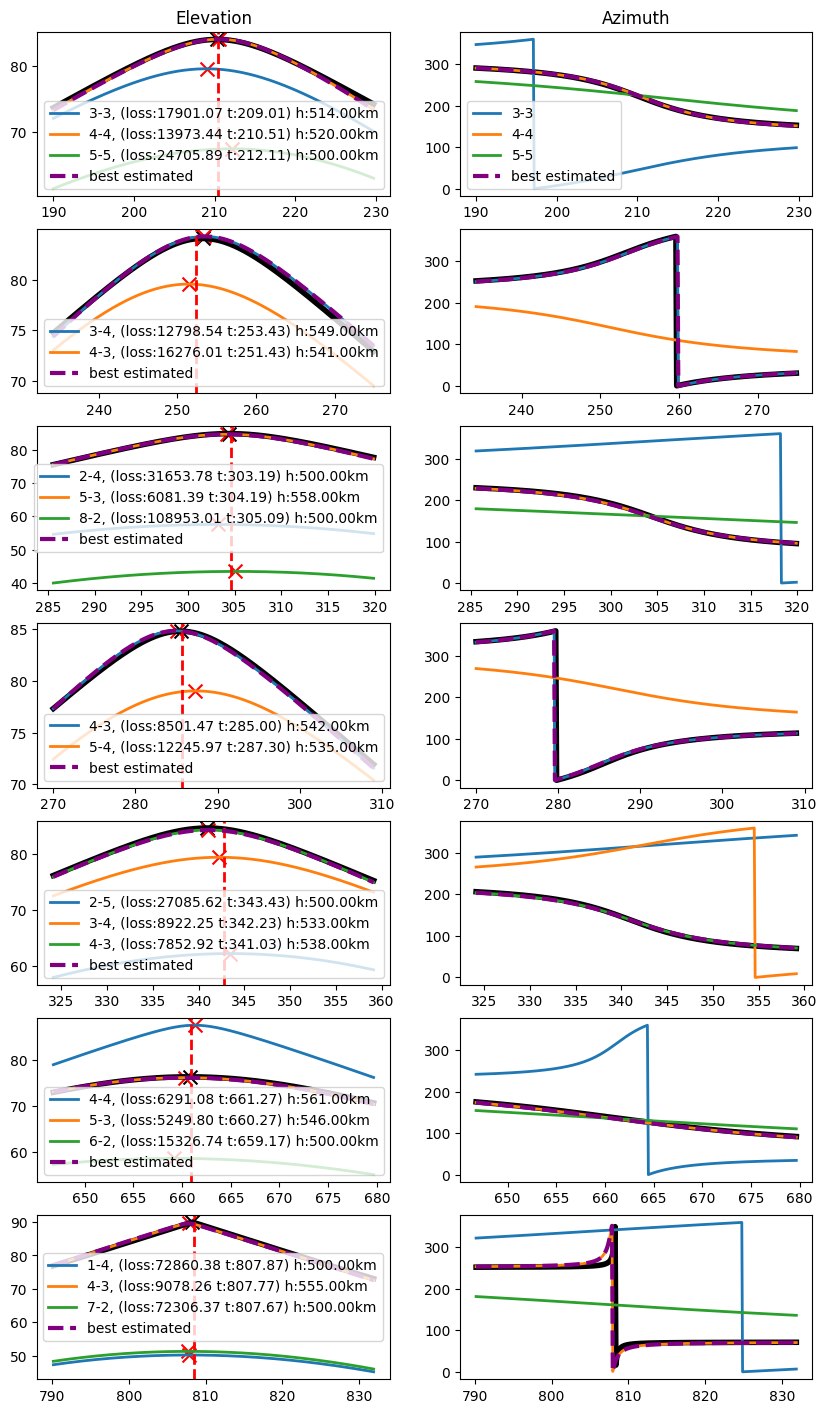

In [7]:
# calculate az and el from the phase difference
plt.figure(figsize=(10, sat_num*2.5))
fig_idx = 1
num_ambiguity = int(d/(lam/2))
del_phi_bound = np.pi*num_ambiguity
best_az_arr = []
best_el_arr = []
best_ambiguity = []
orbit_height_est_list = []
best_el_list, best_az_list = [], []

minmum_elevation = 30 # degrees
t_diff_threshold = 2 # seconds
for sat_idx in range(sat_num):
    print('Satellite index: ', sat_idx)
    plt.subplot(sat_num, 2, fig_idx)
    plt.plot(timestamps_list[sat_idx], np.rad2deg(el_gt_list[sat_idx]), color='black', linewidth=4)
    plt.scatter(timestamps_list[sat_idx][np.argmax(el_gt_list[sat_idx])], np.rad2deg(el_gt_list[sat_idx][np.argmax(el_gt_list[sat_idx])]), marker='x', color='black', s=100)
    plt.subplot(sat_num, 2, fig_idx+1)
    plt.plot(timestamps_list[sat_idx], np.rad2deg(az_gt_list[sat_idx]), color='black', linewidth=4)
    
    del_phi_01_fin = np.polyval(del_phi_01_polyrefit_list[sat_idx], timestamps_list[sat_idx])
    del_phi_12_fin = np.polyval(del_phi_12_polyrefit_list[sat_idx], timestamps_list[sat_idx])
    #get all possible del_phi_01 for sat_idx
    del_phi_01_all = np.zeros((num_ambiguity, len(del_phi_01_fin)))
    ambiguity_vals_01 = np.zeros(num_ambiguity)
    for i in range(num_ambiguity):
        del_phi_01_all[i,:] = del_phi_01_fin + 2*np.pi*(i-num_ambiguity//2)
        ambiguity_vals_01[i] = 2*np.pi*(i-num_ambiguity//2)

    # get all possible del_phi_12 for sat_idx
    del_phi_12_all = np.zeros((num_ambiguity, len(del_phi_12_fin)))
    ambiguity_vals_12 = np.zeros(num_ambiguity)
    for i in range(num_ambiguity):
        del_phi_12_all[i,:] = del_phi_12_fin + 2*np.pi*(i-num_ambiguity//2)
        ambiguity_vals_12[i] = 2*np.pi*(i-num_ambiguity//2)

    del_phi_01_valid_idx = (np.max(del_phi_01_all, axis=1) < del_phi_bound) & (np.min(del_phi_01_all, axis=1) > -del_phi_bound)
    del_phi_12_valid_idx = (np.max(del_phi_12_all, axis=1) < del_phi_bound) & (np.min(del_phi_12_all, axis=1) > -del_phi_bound)
    valid_ambiguity_01 = ambiguity_vals_01[del_phi_01_valid_idx]
    valid_ambiguity_12 = ambiguity_vals_12[del_phi_12_valid_idx]
    del_phi_01_valid = del_phi_01_all[del_phi_01_valid_idx, :]
    del_phi_12_valid = del_phi_12_all[del_phi_12_valid_idx, :]
    num_ambiguity_2d = len(del_phi_01_valid) * len(del_phi_12_valid)
    
    # get dopp coefficients
    dopp_coeff = dopp_coeff_list[sat_idx]
    dopp_curve = np.polyval(dopp_coeff, timestamps_list[sat_idx])
    dopp_curve_zero_cfo = dopp_curve - np.polyval(dopp_coeff, time_arr[sat_idx])
    diff_dopp_grad = np.gradient(dopp_curve, timestamps_list[sat_idx][1]-timestamps_list[sat_idx][0])
    # dopp_rate = np.polyfit(timestamps_list[sat_idx], dopp_curve, 1)[0]
    dopp_rate = np.min(diff_dopp_grad)

    el_max_time_diff = np.inf
    best_amb_01, best_amb_12 = None, None
    best_el, best_az = None, None
    best_i, best_j = None, None
    best_std = np.inf
    best_min_diffelev_time = np.inf
    best_score = -np.inf

    loss_topk, ij_topk, az_fin_topk, el_fin_topk, vsat_topk, hsat_topk = [], [], [], [], [], []
    for i in range(len(del_phi_01_valid)):
        for j in range(len(del_phi_12_valid)):
            if sat_idx == 3 and i == 3 and j == 5:
                print("debug here")
            if sat_idx == 3 and i == 4 and j == 4:
                print("debug here")
            del_phi_01 = del_phi_01_valid[i]
            del_phi_12 = del_phi_12_valid[j]

            # az_fin = np.arctan2(-del_phi_01, -del_phi_12)
            # el_fin = np.arccos(lam/(2*np.pi)*np.sqrt((del_phi_01/d)**2 + (del_phi_12/d)**2))
            phi = np.arctan2(del_phi_12/d, -del_phi_01/d)
            phi = np.mod(phi, 2*np.pi)
            az_fin = 2*np.pi-phi
            el_fin = np.arccos(-del_phi_01*lam/(2*np.pi*d*np.cos(az_fin)))

            # if use_orientation:
            #     los_unit_vec = np.array([np.cos(el_fin)*np.sin(az_fin), np.cos(el_fin)*np.cos(az_fin), np.sin(el_fin)]).T
            #     los_unit_vec_deoriented = np.dot(R, los_unit_vec.T).T
            #     # get az and el
            #     az_fin = np.arctan2(los_unit_vec_deoriented[:,0], los_unit_vec_deoriented[:,1])
            #     az_fin = np.mod(az_fin, 2*np.pi)
            #     el_fin = np.arcsin(los_unit_vec_deoriented[:,2])

            # # adjust for yaw pitch roll
            R_yaw = np.array([[np.cos(np.deg2rad(-yaw)), -np.sin(np.deg2rad(-yaw)), 0], [np.sin(np.deg2rad(-yaw)), np.cos(np.deg2rad(-yaw)), 0], [0, 0, 1]])
            R_pitch = np.array([[np.cos(np.deg2rad(pitch)), 0, np.sin(np.deg2rad(pitch))], [0, 1, 0], [-np.sin(np.deg2rad(pitch)), 0, np.cos(np.deg2rad(pitch))]])
            R_roll = np.array([[1, 0, 0], [0, np.cos(np.deg2rad(roll)), -np.sin(np.deg2rad(roll))], [0, np.sin(np.deg2rad(roll)), np.cos(np.deg2rad(roll))]])

            R = R_yaw @ R_pitch @ R_roll
            x = np.cos(az_fin)*np.cos(el_fin)
            y = np.sin(az_fin)*np.cos(el_fin)
            z = np.sin(el_fin)

            # adjust for yaw pitch roll
            v_local = np.array([x, y, z]).T
            v_global = np.dot(R, v_local.T).T
            az_fin = np.arctan2(v_global[:,1], v_global[:,0])
            az_fin = np.mod(az_fin, 2*np.pi)
            el_fin= np.arcsin(v_global[:,2])

            # if len(el_fin[np.rad2deg(el_fin)<70])>0.3*(len(el_fin)) or np.any(np.isnan(el_fin)):
            if np.any(np.isnan(el_fin)) or np.nanmin(np.rad2deg(el_fin)) < minmum_elevation:
                continue
            t_el_max = timestamps_list[sat_idx][np.argmax(el_fin)]
            if np.abs(time_arr[sat_idx] - t_el_max) > t_diff_threshold:
                continue

            h_sat_gt = np.mean(range_gt_list[sat_idx])
            h_sat, v_sat = range_estimation(start_time, 500e3, 600e3, 1e3, np.rad2deg(el_fin), np.rad2deg(az_fin), timestamps_list[sat_idx], lat_gt, lon_gt, alt_gt)
            # h_sat, v_sat, inc_sat, range_rate_est = range_estimation_with_inc(start_time, 500e3, 600e3, 1e3, np.rad2deg(el_fin), np.rad2deg(az_fin), timestamps_list[sat_idx], lat_gt, lon_gt, alt_gt)
            # if h_sat == 500e3 or h_sat == 600e3:
            #     continue
            R_earth = 6371e3  # Earth's radius in meters
            c = 3e8  # speed of light in m/s
            R_sat = R_earth + h_sat
            rho = -R_earth * np.sin(el_fin) + np.sqrt(R_sat**2 - (R_earth**2) * (np.cos(el_fin)**2))
            # rho = h_sat/np.sin(el_fin)
            rho_dot = np.gradient(rho, timestamps_list[sat_idx][1]-timestamps_list[sat_idx][0])
            doppler_est = - (fc / c) * rho_dot  # Doppler shift estimation
            # doppler_est = - (fc / c) * range_rate_est
            # doppler_rate_est = np.polyfit(timestamps_list[sat_idx], doppler_est, 1)[0]
            doppler_rate_est = -fc/c*v_sat**2/(h_sat/np.sin(np.max(el_fin)))
            diff_dopp_est = np.gradient(doppler_est, timestamps_list[sat_idx][1]-timestamps_list[sat_idx][0])

            # inc_list = [53, 53.2, 43, 70, 97.6]
            # if np.min(np.abs(inc_sat - inc_list)) > 1:
            #     continue

            # calculate ground truth score
            R_sat_gt = R_earth + h_sat_gt
            rho_gt = -R_earth * np.sin(el_gt_list[sat_idx]) + np.sqrt(R_sat_gt**2 - (R_earth**2) * (np.cos(el_gt_list[sat_idx])**2))
            rho_dot_gt = np.gradient(rho_gt, timestamps_list[sat_idx][1]-timestamps_list[sat_idx][0])
            doppler_gt = - (fc / c) * rho_dot_gt  # Doppler shift estimation
            diff_dopp_gt = np.gradient(doppler_gt, timestamps_list[sat_idx][1]-timestamps_list[sat_idx][0])

            kk = 3
            loss_ij = np.linalg.norm(diff_dopp_grad-diff_dopp_est)
            # loss_ij = np.linalg.norm(doppler_est - dopp_curve_zero_cfo)
            # loss_ij = np.abs(dopp_rate - doppler_rate_est)
            if len(loss_topk) < kk or loss_ij < np.max(loss_topk):
                if len(loss_topk) == kk:
                    max_loss_idx = np.argmax(loss_topk)
                    loss_topk.pop(max_loss_idx)
                    ij_topk.pop(max_loss_idx)
                    az_fin_topk.pop(max_loss_idx)
                    el_fin_topk.pop(max_loss_idx)
                    vsat_topk.pop(max_loss_idx)
                    hsat_topk.pop(max_loss_idx)
                    
                vsat_topk.append(v_sat)
                hsat_topk.append(h_sat)
                az_fin_topk.append(az_fin)
                el_fin_topk.append(el_fin)
                loss_topk.append(loss_ij)
                ij_topk.append((i,j))

    dmin = np.array(vsat_topk)**2*fc/c/np.abs(diff_dopp_grad.mean())
    min_loss = np.inf
    for idx in range(len(loss_topk)):
        i, j = ij_topk[idx]
        el_fin = el_fin_topk[idx]
        az_fin = az_fin_topk[idx]
        el_fin_max_idx = np.argmax(el_fin)
        t_el_max = timestamps_list[sat_idx][el_fin_max_idx]
        h_sat = hsat_topk[idx]

        plt.subplot(sat_num, 2, fig_idx)
        plt.plot(timestamps_list[sat_idx], np.rad2deg(el_fin), label=f"{i}-{j}, (loss:{loss_topk[idx]:.2f} t:{t_el_max:.2f}) h:{h_sat/1e3:.2f}km", linewidth=2)
        plt.scatter(t_el_max, np.rad2deg(el_fin[el_fin_max_idx]), marker='x', color='red', s=100)
        plt.subplot(sat_num, 2, fig_idx+1)
        plt.plot(timestamps_list[sat_idx], np.rad2deg(az_fin), label=f"{i}-{j}", linewidth=2)
        
        # find the best one based on loss
        if loss_topk[idx] < min_loss:
            min_loss = loss_topk[idx]
            best_amb_01, best_amb_12 = valid_ambiguity_01[i], valid_ambiguity_12[j]
            best_el, best_az = el_fin, az_fin
            best_i, best_j = i, j
            best_h_sat = h_sat
    best_ambiguity.append((best_amb_01, best_amb_12))
    orbit_height_est_list.append(best_h_sat)
    best_el_list.append(best_el)
    best_az_list.append(best_az)
    
    plt.subplot(sat_num, 2, fig_idx)
    plt.axvline(x=time_arr[sat_idx], color='red', linestyle='--', linewidth=2)
    plt.plot(timestamps_list[sat_idx], np.rad2deg(best_el), '--', label="best estimated", color='purple', linewidth=3)
    # plt.ylim(70, 90)
    # plt.plot(t, np.rad2deg(el_gt_fin), '.', label="best raw", color='purple')
    if sat_idx == 0:
        plt.title("Elevation")
    plt.legend()
    plt.subplot(sat_num, 2, fig_idx+1)
    plt.plot(timestamps_list[sat_idx], np.rad2deg(best_az), '--', label="best estimated", color='purple', linewidth=3)
    # plt.plot(t, np.rad2deg(az_gt_fin), '.', label="best raw", color='purple')
    if sat_idx == 0:
        plt.title("Azimuth")
        plt.legend() 
    
    fig_idx += 2



/var/folders/2k/nst1mls11d9_hrj8jjh1vpkh0000gn/T/ipykernel_25909/2894156397.py:57: RuntimeWarning: invalid value encountered in arccos
  el_baseline_fin = np.arccos(-del_phi_01_baseline*lam/(2*np.pi*(d / 10)*np.cos(az_baseline_fin)))


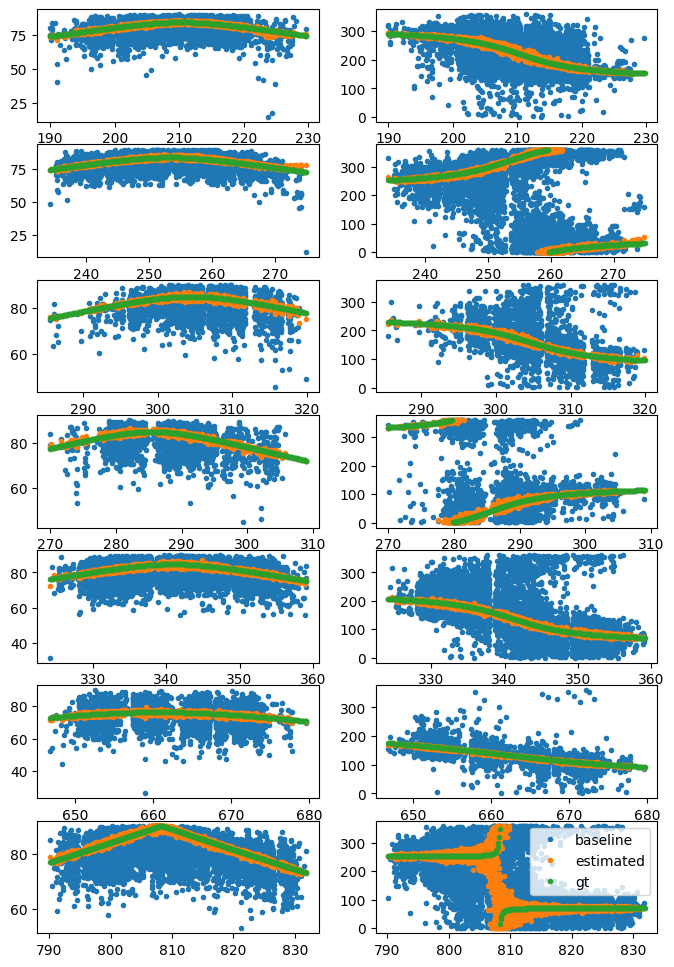

In [8]:

# baseline
del_phi_01_baseline_list, del_phi_12_baseline_list = [], []
el_baseline_list, az_baseline_list = [], []
pointing_err_list, pointing_err_baseline_list = [], []
best_az_origphase, best_el_origphase = [], []
plt.figure(figsize=(8,12))
fig_idx = 1
az_gt_origphase_list, el_gt_origphase_list, range_gt_origphase_list = [], [], []

for sat_idx in range(sat_num):
    sat_dopp_track = tones_dict[0, sat_idx]
    t = sat_dopp_track[:, 0].real

    del_phi_01_alltones_gapcompensated = del_phi_01_alltones_comp_list[sat_idx]+best_ambiguity[sat_idx][0]
    del_phi_12_alltones_gapcompensated = del_phi_12_alltones_comp_list[sat_idx]+best_ambiguity[sat_idx][1]
    
    phi = np.arctan2(del_phi_12_alltones_gapcompensated/d, -del_phi_01_alltones_gapcompensated/d)
    phi = np.mod(phi, 2*np.pi)
    az_fin = 2*np.pi-phi
    el_fin = np.arccos(-del_phi_01_alltones_gapcompensated*lam/(2*np.pi*d*np.cos(az_fin)))

    # if use_orientation:
    #     los_unit_vec = np.array([np.cos(el_fin)*np.sin(az_fin), np.cos(el_fin)*np.cos(az_fin), np.sin(el_fin)]).T
    #     # apply inverse rotation
    #     los_unit_vec_deoriented = np.dot(R, los_unit_vec.T).T
    #     # get az and el
    #     az_fin = np.arctan2(los_unit_vec_deoriented[:,1], los_unit_vec_deoriented[:,0])
    #     az_fin = np.mod(az_fin, 2*np.pi)
    #     el_fin = np.arcsin(los_unit_vec_deoriented[:,2])

    coeff_01_gt = np.polyfit(timestamps_list[sat_idx], del_phi_01_gt_list[sat_idx], 2)
    coeff_12_gt = np.polyfit(timestamps_list[sat_idx], del_phi_12_gt_list[sat_idx], 2)
    az_gt = 2*np.pi - np.arctan2(np.polyval(coeff_12_gt, t)/d, -np.polyval(coeff_01_gt, t)/d)
    el_gt = np.arccos(-np.polyval(coeff_01_gt, t)*lam/(2*np.pi*d*np.cos(az_gt)))
    az_gt_origphase_list.append(az_gt)
    el_gt_origphase_list.append(el_gt)

    coeff_01_t = np.polyfit(t, del_phi_01_alltones_gapcompensated, 2)
    coeff_12_t = np.polyfit(t, del_phi_12_alltones_gapcompensated, 2)
    del_phi_01_baseline = np.polyval(coeff_01_t, t) / 10
    del_phi_12_baseline = np.polyval(coeff_12_t, t) / 10
    for i in range(len(del_phi_01_baseline)):
        t_i = t[i]
        noise_01 = del_phi_01_alltones_gapcompensated[i] - np.polyval(coeff_01_t, t_i)
        noise_12 = del_phi_12_alltones_gapcompensated[i] - np.polyval(coeff_12_t, t_i)
        del_phi_01_baseline[i] = del_phi_01_baseline[i] + noise_01
        del_phi_12_baseline[i] = del_phi_12_baseline[i] + noise_12
        # make sure they are withink -pi to pi
        while np.abs(del_phi_01_baseline[i]) > np.pi:
            del_phi_01_baseline[i] = del_phi_01_baseline[i] - np.sign(del_phi_01_baseline[i])*2*np.pi
        while np.abs(del_phi_12_baseline[i]) > np.pi:
            del_phi_12_baseline[i] = del_phi_12_baseline[i] - np.sign(del_phi_12_baseline[i])*2*np.pi
    
    phi_baseline = np.arctan2(del_phi_12_baseline, -del_phi_01_baseline)
    phi_baseline = np.mod(phi_baseline, 2*np.pi)
    az_baseline_fin = 2*np.pi-phi_baseline
    el_baseline_fin = np.arccos(-del_phi_01_baseline*lam/(2*np.pi*(d / 10)*np.cos(az_baseline_fin)))


    # los_unit_vec = np.array([np.cos(el_baseline_fin)*np.sin(az_baseline_fin), np.cos(el_baseline_fin)*np.cos(az_baseline_fin), np.sin(el_baseline_fin)]).T
    # # apply inverse rotation
    # los_unit_vec_deoriented = np.dot(R, los_unit_vec.T).T
    # # get az and el
    # az_baseline_fin = np.arctan2(los_unit_vec_deoriented[:,1], los_unit_vec_deoriented[:,0])
    # az_baseline_fin = np.mod(az_baseline_fin, 2*np.pi)
    # el_baseline_fin = np.arcsin(los_unit_vec_deoriented[:,2])

    del_phi_01_baseline_list.append(del_phi_01_baseline)
    del_phi_12_baseline_list.append(del_phi_12_baseline)
    el_baseline_list.append(el_baseline_fin)
    az_baseline_list.append(az_baseline_fin)

    x = np.cos(az_fin)*np.cos(el_fin)
    y = np.sin(az_fin)*np.cos(el_fin)
    z = np.sin(el_fin)
    # adjust for yaw pitch roll
    v_local = np.array([x, y, z]).T
    v_global = np.dot(R, v_local.T).T
    x, y, z = v_global[:,0], v_global[:,1], v_global[:,2]
    az_fin = np.arctan2(v_global[:,1], v_global[:,0])
    az_fin = np.mod(az_fin, 2*np.pi)
    el_fin = np.arcsin(v_global[:,2])
    best_az_origphase.append(az_fin)
    best_el_origphase.append(el_fin)

    
    # upsample to match timestamps
    range_gt = range_gt_list[sat_idx]
    cs = CubicSpline(timestamps_list[sat_idx], range_gt)
    range_gt_upsampled = cs(t)
    range_gt_origphase_list.append(range_gt_upsampled)
    
    x_baseline = np.cos(az_baseline_fin)*np.cos(el_baseline_fin)
    y_baseline = np.sin(az_baseline_fin)*np.cos(el_baseline_fin)
    z_baseline = np.sin(el_baseline_fin)
    # adjust for yaw pitch roll
    v_local_baseline = np.array([x_baseline, y_baseline, z_baseline]).T
    v_global_baseline = np.dot(R, v_local_baseline.T).T
    x_baseline, y_baseline, z_baseline = v_global_baseline[:,0], v_global_baseline[:,1], v_global_baseline[:,2]
    az_baseline_fin = np.arctan2(v_global_baseline[:,1], v_global_baseline[:,0])
    az_baseline_fin = np.mod(az_baseline_fin, 2*np.pi)
    el_baseline_fin = np.arcsin(v_global_baseline[:,2])

    x_gt = np.cos(az_gt)*np.cos(el_gt)
    y_gt = np.sin(az_gt)*np.cos(el_gt)
    z_gt = np.sin(el_gt)
    v = np.array([x, y, z]).T
    v_baseline = np.array([x_baseline, y_baseline, z_baseline]).T
    v_gt = np.array([x_gt, y_gt, z_gt]).T
    dot_prods = np.sum(v*v_gt, axis=1)
    dot_prods_baseline = np.sum(v_baseline*v_gt, axis=1)
    norms1 = np.linalg.norm(v, axis=1)
    norms2 = np.linalg.norm(v_gt, axis=1)
    norms3 = np.linalg.norm(v_baseline, axis=1)
    cosines = dot_prods/(norms1*norms2)
    cosines_baseline = dot_prods_baseline/(norms3*norms2)
    pointing_error_angle = np.arccos(cosines)
    pointing_err_list.append(pointing_error_angle)
    pointing_error_angle_baseline = np.arccos(cosines_baseline)
    pointing_err_baseline_list.append(pointing_error_angle_baseline)

    plt.subplot(sat_num, 2, fig_idx)
    plt.plot(t, np.rad2deg(el_baseline_fin), '.', label='baseline')
    plt.plot(t, np.rad2deg(el_fin), '.', label='estimated')
    plt.plot(timestamps_list[sat_idx], np.rad2deg(el_gt_list[sat_idx]), '.', label='gt')
    plt.subplot(sat_num, 2, fig_idx+1)
    plt.plot(t, np.rad2deg(az_baseline_fin), '.', label='baseline')
    plt.plot(t, np.rad2deg(az_fin), '.', label='estimated')
    plt.plot(timestamps_list[sat_idx], np.rad2deg(az_gt_list[sat_idx]), '.', label='gt')
    fig_idx += 2

plt.legend()
plt.show()

In [9]:
# # save best az array
# res_folder = 'results/'
# dict_res = {}
# dict_res_baseline = {}
# for sat_idx in range(sat_num):
#     best_az_i = best_az_origphase[sat_idx]
#     best_el_i = best_el_origphase[sat_idx]
#     az_i_baseline = az_baseline_list[sat_idx]
#     el_i_baseline = el_baseline_list[sat_idx]
#     pointing_err = pointing_err_list[sat_idx]
#     pointing_err_baseline = pointing_err_baseline_list[sat_idx]
#     az_gt_origphase = az_gt_origphase_list[sat_idx]
#     el_gt_origphase = el_gt_origphase_list[sat_idx]
#     range_gt = range_gt_list[sat_idx]
#     orbit_height_est = orbit_height_est_list[sat_idx]
#     timestamps_i = timestamps_list[sat_idx]
#     az_gt = az_gt_list[sat_idx]
#     el_gt = el_gt_list[sat_idx]
#     el_best = best_el_list[sat_idx]
#     az_best = best_az_list[sat_idx]
#     orbit_hight_gt = range_gt[np.argmax(el_gt)] * np.sin(el_gt[np.argmax(el_gt)])

#     dict_res[sat_idx] = {'orbit_height_gt': orbit_hight_gt.item(), 'orbit_height_est': orbit_height_est.item(), 'range_gt_origphase': range_gt_origphase_list[sat_idx].tolist(), 'az_origphase': best_az_i.tolist(), 'el_origphase': best_el_i.tolist(), 'az_baseline_origphase': az_i_baseline.tolist(), 'el_baseline_origphase': el_i_baseline.tolist(), 'pointing_err_origphase': pointing_err.tolist(), 'pointing_err_baseline_origphase': pointing_err_baseline.tolist(), 'az_gt_origphase': az_gt_origphase.tolist(), 'el_gt_origphase': el_gt_origphase.tolist(), 'az_best': az_best.tolist(), 'el_best': el_best.tolist(), 'az_gt': az_gt.tolist(), 'el_gt': el_gt.tolist(), 'range_gt': range_gt.tolist(), 'dopp_gt': dopp_gt_list[sat_idx].tolist(), 'timestamps': timestamps_i.tolist()}

# starloc_config = {'date': date, 'lat_gt': lat_gt, 'lon_gt': lon_gt, 'alt_gt': alt_gt, 'sat_num': sat_num, 'train_num': train_num}
# dict_res['__starloc_config__'] = starloc_config


# print(dict_res)
# with open(os.path.join(res_folder, date+'.json'), 'w') as f:
#     json.dump(dict_res, f)